In [1]:

%pip -q install xgboost scikit-learn pandas numpy matplotlib seaborn kagglehub joblib


In [2]:

import sys
import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import matplotlib
import seaborn as sns
import kagglehub

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

print("\nEnvironment ready!")


Python: 3.13.16
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1
Matplotlib: 3.10.0
Seaborn: 0.13.2

Environment ready!


In [3]:

import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download(
        "prasadnirmal/srilankan-second-vehiclecar-price-dataset"
    )
)

print("Dataset location:", dataset_path)

print("\nFiles downloaded:")
for file in dataset_path.rglob("*"):
    if file.is_file():
        print(file.relative_to(dataset_path), "-", file.stat().st_size, "bytes")


Using Colab cache for faster access to the 'srilankan-second-vehiclecar-price-dataset' dataset.
Dataset location: /kaggle/input/srilankan-second-vehiclecar-price-dataset

Files downloaded:
car_price_dataset.csv - 1401533 bytes


In [4]:

import pandas as pd
from pathlib import Path

csv_files = list(dataset_path.rglob("*.csv"))

print("CSV files found:")
for i, file in enumerate(csv_files):
    print(f"{i}: {file.name}")

if not csv_files:
    raise FileNotFoundError("No CSV files found!")

# Load the first CSV file
df = pd.read_csv(csv_files[0])

print("\nDataset shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())


CSV files found:
0: car_price_dataset.csv

Dataset shape: (9788, 17)

First 5 records:


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [5]:

print("COLUMN INFORMATION")
print("=" * 60)

df.info()

print("\nCOLUMN NAMES")
print("=" * 60)

for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

print("\nDATA TYPES")
print("=" * 60)

display(df.dtypes.to_frame("Data Type"))


COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9788 entries, 0 to 9787
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      9788 non-null   int64  
 1   Brand           9788 non-null   object 
 2   Model           9788 non-null   object 
 3   YOM             9788 non-null   int64  
 4   Engine (cc)     9788 non-null   float64
 5   Gear            9788 non-null   object 
 6   Fuel Type       9788 non-null   object 
 7   Millage(KM)     9788 non-null   float64
 8   Town            9788 non-null   object 
 9   Date            9788 non-null   object 
 10  Leasing         9788 non-null   object 
 11  Condition       9788 non-null   object 
 12  AIR CONDITION   9788 non-null   object 
 13  POWER STEERING  9788 non-null   object 
 14  POWER MIRROR    9788 non-null   object 
 15  POWER WINDOW    9788 non-null   object 
 16  Price           9788 non-null   float64
dtypes: float64(3),

,Data Type
Unnamed: 0,int64
Brand,object
Model,object
YOM,int64
Engine (cc),float64
Gear,object
Fuel Type,object
Millage(KM),float64
Town,object
Date,object


In [6]:

print("MISSING VALUES")
print("=" * 60)

missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})

display(missing.sort_values("Missing Count", ascending=False))

print("\nDUPLICATE ROWS")
print("=" * 60)

print("Total duplicate rows:", df.duplicated().sum())

print("\nTOTAL RECORDS:", len(df))


MISSING VALUES


,Missing Count,Missing %
Unnamed: 0,0,0.0
Brand,0,0.0
Model,0,0.0
YOM,0,0.0
Engine (cc),0,0.0
Gear,0,0.0
Fuel Type,0,0.0
Millage(KM),0,0.0
Town,0,0.0
Date,0,0.0



DUPLICATE ROWS
Total duplicate rows: 0

TOTAL RECORDS: 9788


In [7]:

print("NUMERICAL COLUMN STATISTICS")
print("=" * 60)

display(df.describe(include="number").T)

print("\nCATEGORICAL COLUMN STATISTICS")
print("=" * 60)

display(df.describe(include=["object", "category"]).T)


NUMERICAL COLUMN STATISTICS


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,9788.0,4893.758991,2826.028988,0.00,2446.75,4893.5,7341.25,9788.0
YOM,9788.0,2006.759093,9.831574,1956.00,2001.00,2009.0,2015.00,2024.0
Engine (cc),9788.0,1260.442358,403.769059,573.00,1000.00,1300.0,1500.00,4800.0
Millage(KM),9788.0,200649.979567,108147.314860,11000.00,110000.00,176000.0,264000.00,759000.0
Price,9788.0,53.464275,43.625049,2.65,26.25,43.0,69.75,790.0



CATEGORICAL COLUMN STATISTICS


,count,unique,top,freq
Brand,9788,50,TOYOTA,3089
Model,9788,1555,ALTO,392
Gear,9788,2,Automatic,6305
Fuel Type,9788,4,Petrol,7866
Town,9788,107,Colombo,1038
Date,9788,65,2025-02-05,645
Leasing,9788,2,No Leasing,9384
Condition,9788,2,USED,9694
AIR CONDITION,9788,2,Available,9590
POWER STEERING,9788,2,Available,8918


In [8]:

print("UNIQUE VALUES PER COLUMN")
print("=" * 60)

for col in df.columns:
    print(f"\nColumn: {col}")
    print("Unique count:", df[col].nunique(dropna=True))

    if df[col].nunique(dropna=True) <= 20:
        print(df[col].value_counts(dropna=False).head(20).to_string())
    else:
        print(df[col].value_counts(dropna=False).head(5).to_string())


UNIQUE VALUES PER COLUMN

Column: Unnamed: 0
Unique count: 9788
Unnamed: 0
9788    1
0       1
1       1
2       1
3       1

Column: Brand
Unique count: 50
Brand
TOYOTA        3089
SUZUKI        2473
NISSAN        1248
HONDA          681
MITSUBISHI     284

Column: Model
Unique count: 1555
Model
ALTO                392
VITZ                366
WAGON R STINGRAY    282
MARUTI              229
WAGON R             204

Column: YOM
Unique count: 62
YOM
2015    836
2017    612
2007    558
2016    549
2018    530

Column: Engine (cc)
Unique count: 278
Engine (cc)
1500.0    2564
1000.0    1379
1300.0    1110
800.0      897
650.0      685

Column: Gear
Unique count: 2
Gear
Automatic    6305
Manual       3483

Column: Fuel Type
Unique count: 4
Fuel Type
Petrol      7866
Hybrid      1239
Diesel       614
Electric      69

Column: Millage(KM)
Unique count: 62
Millage(KM)
110000.0    836
88000.0     612
198000.0    558
99000.0     549
77000.0     530

Column: Town
Unique count: 107
Town
Colombo    

In [9]:

print("PRICE STATISTICS")
print("=" * 50)

print(df["Price"].describe())

print("\nLowest 10 prices:")
display(df.nsmallest(10, "Price")[
    ["Brand", "Model", "YOM", "Price"]
])

print("\nHighest 10 prices:")
display(df.nlargest(10, "Price")[
    ["Brand", "Model", "YOM", "Price"]
])

print("\nZero or negative prices:")
print((df["Price"] <= 0).sum())


PRICE STATISTICS
count    9788.000000
mean       53.464275
std        43.625049
min         2.650000
25%        26.250000
50%        43.000000
75%        69.750000
max       790.000000
Name: Price, dtype: float64

Lowest 10 prices:


,Brand,Model,YOM,Price
8401,TOYOTA,KE50,1980,2.65
2103,MITSUBISHI,COLT,1979,3.25
2131,MITSUBISHI,GALANT,1975,3.40
2488,NISSAN,B310,1979,3.65
2165,MITSUBISHI,LANCER,1983,3.75
8415,TOYOTA,LADA RIVA,1986,3.75
2338,MITSUBISHI,LANCER WAGON,1978,3.88
1310,ISUZU,GEMINI,1988,3.90
1621,MAZDA,MAZDA,1993,4.00
2454,NISSAN,B11 CALIFORNIA,1986,4.00



Highest 10 prices:


,Brand,Model,YOM,Price
8417,TOYOTA,LEXUS 600HL,2011,790.0
138,BMW,740LE M SPORT,2016,575.0
1776,MERCEDES-BENZ,S400 LONG WHEEL BASE,2015,550.0
55,AUDI,Q4,2024,475.0
133,BMW,530I M SPORT,2017,460.0
109,BMW,430I GRAN COUPE,2017,450.0
153,BMW,M SPORT,2018,425.0
1733,MERCEDES-BENZ,E200,2016,405.0
159,BYD,SEAL,2024,394.5
148,BMW,G30 530I,2017,380.0



Zero or negative prices:
0


In [10]:

print("COLUMN TYPES AND MISSING VALUES")
print("=" * 60)

summary = pd.DataFrame({
    "Type": df.dtypes.astype(str),
    "Missing": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

display(summary)

print("\nDuplicate records (excluding exported index):")
print(df.drop(columns=["Unnamed: 0"], errors="ignore").duplicated().sum())

print("\nDate range:")
dates = pd.to_datetime(df["Date"], errors="coerce")
print("Earliest:", dates.min())
print("Latest:", dates.max())
print("Invalid dates:", dates.isna().sum())


COLUMN TYPES AND MISSING VALUES


,Type,Missing,Missing %,Unique Values
Unnamed: 0,int64,0,0.0,9788
Brand,object,0,0.0,50
Model,object,0,0.0,1555
YOM,int64,0,0.0,62
Engine (cc),float64,0,0.0,278
Gear,object,0,0.0,2
Fuel Type,object,0,0.0,4
Millage(KM),float64,0,0.0,62
Town,object,0,0.0,107
Date,object,0,0.0,65



Duplicate records (excluding exported index):
18

Date range:
Earliest: 2024-12-03 00:00:00
Latest: 2025-02-05 00:00:00
Invalid dates: 0


In [11]:

import pandas as pd
import numpy as np

# Preserve the original dataset
df_work = df.copy()

# Remove the exported index column only
df_work = df_work.drop(columns=["Unnamed: 0"], errors="ignore")

print("Dataset shape:", df_work.shape)

print("\nVEHICLE YEAR STATISTICS")
print(df_work["YOM"].describe())

print("\nENGINE CAPACITY STATISTICS")
print(df_work["Engine (cc)"].describe())

print("\nMILEAGE STATISTICS")
print(df_work["Millage(KM)"].describe())

print("\nMOST COMMON MILEAGE VALUES")
display(df_work["Millage(KM)"].value_counts().head(15))

print("\nCATEGORICAL VALUES")
for col in [
    "Gear", "Fuel Type", "Leasing", "Condition",
    "AIR CONDITION", "POWER STEERING",
    "POWER MIRROR", "POWER WINDOW"
]:
    print(f"\n{col}")
    print(df_work[col].value_counts(dropna=False).to_string())

print("\nDUPLICATE LISTINGS")
duplicates = df_work[
    df_work.duplicated(keep=False)
].sort_values(["Brand", "Model", "Price"])

print("Rows in duplicate groups:", len(duplicates))
display(duplicates.head(12))


Dataset shape: (9788, 16)

VEHICLE YEAR STATISTICS
count    9788.000000
mean     2006.759093
std         9.831574
min      1956.000000
25%      2001.000000
50%      2009.000000
75%      2015.000000
max      2024.000000
Name: YOM, dtype: float64

ENGINE CAPACITY STATISTICS
count    9788.000000
mean     1260.442358
std       403.769059
min       573.000000
25%      1000.000000
50%      1300.000000
75%      1500.000000
max      4800.000000
Name: Engine (cc), dtype: float64

MILEAGE STATISTICS
count      9788.000000
mean     200649.979567
std      108147.314860
min       11000.000000
25%      110000.000000
50%      176000.000000
75%      264000.000000
max      759000.000000
Name: Millage(KM), dtype: float64

MOST COMMON MILEAGE VALUES


,count
Millage(KM),
110000.0,836
88000.0,612
198000.0,558
99000.0,549
77000.0,530
154000.0,497
121000.0,486
187000.0,426
143000.0,425



CATEGORICAL VALUES

Gear
Gear
Automatic    6305
Manual       3483

Fuel Type
Fuel Type
Petrol      7866
Hybrid      1239
Diesel       614
Electric      69

Leasing
Leasing
No Leasing       9384
Ongoing Lease     404

Condition
Condition
USED    9694
NEW       94

AIR CONDITION
AIR CONDITION
Available        9590
Not_Available     198

POWER STEERING
POWER STEERING
Available        8918
Not_Available     870

POWER MIRROR
POWER MIRROR
Available        7281
Not_Available    2507

POWER WINDOW
POWER WINDOW
Available        8003
Not_Available    1785

DUPLICATE LISTINGS
Rows in duplicate groups: 36


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
90,BMW,318I M SPORT AUSTRALIAN,2018,1500.0,Automatic,Petrol,77000.0,Nugegoda,2025-01-30,No Leasing,USED,Available,Available,Available,Available,280.000000
91,BMW,318I M SPORT AUSTRALIAN,2018,1500.0,Automatic,Petrol,77000.0,Nugegoda,2025-01-30,No Leasing,USED,Available,Available,Available,Available,280.000000
1000,HONDA,GRACE EX GRADE,2015,1500.0,Automatic,Hybrid,110000.0,Nugegoda,2025-01-28,No Leasing,USED,Available,Available,Available,Available,110.950000
1001,HONDA,GRACE EX GRADE,2015,1500.0,Automatic,Hybrid,110000.0,Nugegoda,2025-01-28,No Leasing,USED,Available,Available,Available,Available,110.950000
1237,HYUNDAI,EON MAGNA PLUS,2015,814.0,Manual,Petrol,110000.0,Kalmunai,2025-01-11,No Leasing,USED,Available,Available,Available,Available,36.100000
1238,HYUNDAI,EON MAGNA PLUS,2015,814.0,Manual,Petrol,110000.0,Kalmunai,2025-01-11,No Leasing,USED,Available,Available,Available,Available,36.100000
2892,NISSAN,FB15,2000,1500.0,Automatic,Petrol,275000.0,Kandy,2024-12-18,No Leasing,USED,Available,Available,Available,Available,35.047619
2893,NISSAN,FB15,2000,1500.0,Automatic,Petrol,275000.0,Kandy,2024-12-18,No Leasing,USED,Available,Available,Available,Available,35.047619
3787,PERODUA,VIVA ELITE,2011,1000.0,Automatic,Petrol,154000.0,Colombo,2025-01-06,No Leasing,USED,Available,Available,Available,Available,36.250000
3788,PERODUA,VIVA ELITE,2011,1000.0,Automatic,Petrol,154000.0,Colombo,2025-01-06,No Leasing,USED,Available,Available,Available,Available,36.250000


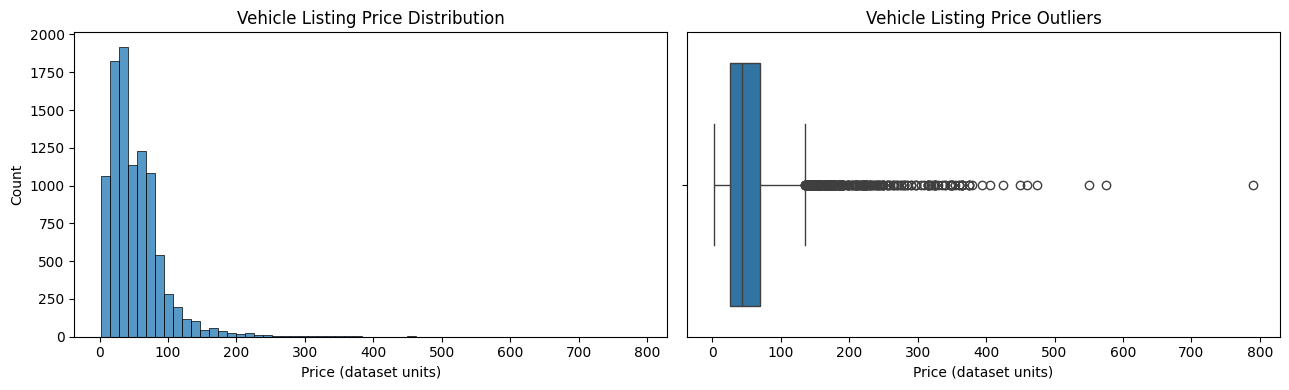

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_work["Price"],
    bins=60,
    ax=axes[0]
)
axes[0].set_title("Vehicle Listing Price Distribution")
axes[0].set_xlabel("Price (dataset units)")

sns.boxplot(
    x=df_work["Price"],
    ax=axes[1]
)
axes[1].set_title("Vehicle Listing Price Outliers")
axes[1].set_xlabel("Price (dataset units)")

plt.tight_layout()
plt.show()


In [13]:

# Start from the working copy created earlier
df_clean = df_work.copy()

# Remove exact duplicate rows
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Original records:", before)
print("After duplicate removal:", len(df_clean))
print("Removed:", before - len(df_clean))

# Inspect mileage patterns
mileage = df_clean["Millage(KM)"]

multiples_of_11000 = (mileage % 11000 == 0).mean() * 100

print("\nMILEAGE QUALITY CHECK")
print("Percentage divisible by 11,000:",
      round(multiples_of_11000, 2), "%")

print("Unique mileage values:", mileage.nunique())

print("\nFirst 30 unique mileage values:")
print(sorted(mileage.unique())[:30])

print("\nPRICE QUALITY CHECK")
print("Minimum price:", df_clean["Price"].min())
print("Maximum price:", df_clean["Price"].max())
print("Missing target values:", df_clean["Price"].isna().sum())


Original records: 9788
After duplicate removal: 9770
Removed: 18

MILEAGE QUALITY CHECK
Percentage divisible by 11,000: 100.0 %
Unique mileage values: 62

First 30 unique mileage values:
[np.float64(11000.0), np.float64(22000.0), np.float64(33000.0), np.float64(44000.0), np.float64(55000.0), np.float64(66000.0), np.float64(77000.0), np.float64(88000.0), np.float64(99000.0), np.float64(110000.0), np.float64(121000.0), np.float64(132000.0), np.float64(143000.0), np.float64(154000.0), np.float64(165000.0), np.float64(176000.0), np.float64(187000.0), np.float64(198000.0), np.float64(209000.0), np.float64(220000.0), np.float64(231000.0), np.float64(242000.0), np.float64(253000.0), np.float64(264000.0), np.float64(275000.0), np.float64(286000.0), np.float64(297000.0), np.float64(308000.0), np.float64(319000.0), np.float64(330000.0)]

PRICE QUALITY CHECK
Minimum price: 2.65
Maximum price: 790.0
Missing target values: 0


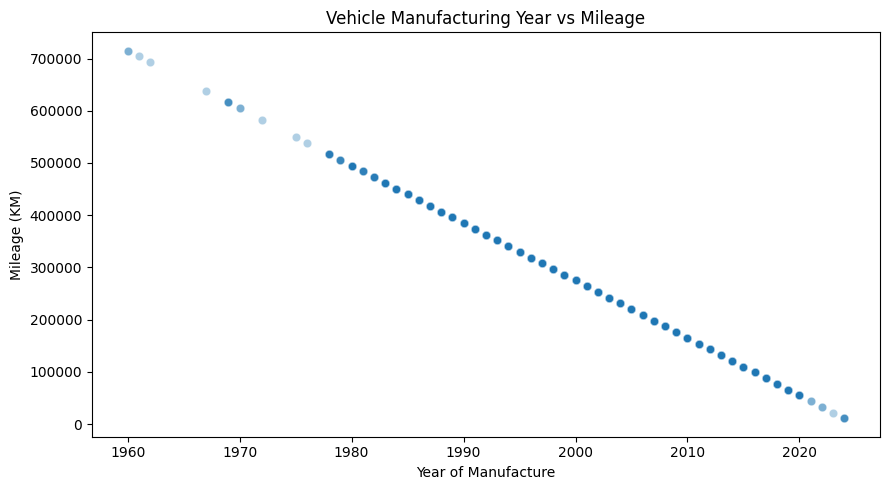


CORRELATION
               YOM  Millage(KM)  Price
YOM          1.000       -1.000  0.507
Millage(KM) -1.000        1.000 -0.507
Price        0.507       -0.507  1.000


In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

sample = df_clean.sample(
    n=min(3000, len(df_clean)),
    random_state=42
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=sample,
    x="YOM",
    y="Millage(KM)",
    alpha=0.35
)

plt.title("Vehicle Manufacturing Year vs Mileage")
plt.xlabel("Year of Manufacture")
plt.ylabel("Mileage (KM)")
plt.tight_layout()
plt.show()

print("\nCORRELATION")
print(
    df_clean[["YOM", "Millage(KM)", "Price"]]
    .corr()
    .round(3)
)


In [15]:

from sklearn.model_selection import train_test_split

# Select features
X = df_clean.drop(columns=["Price", "Date"])

# Prediction target
y = df_clean["Price"]

# Consistent split for both models
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nSelected features:")
print(X.columns.tolist())

print("\nTarget:", y.name)


Training records: 7816
Testing records: 1954

Selected features:
['Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Millage(KM)', 'Town', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']

Target: Price


In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Numeric features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nPreprocessing pipeline ready.")


Numeric features: ['YOM', 'Engine (cc)', 'Millage(KM)']

Categorical features: ['Brand', 'Model', 'Gear', 'Fuel Type', 'Town', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']

Preprocessing pipeline ready.


In [17]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
import time

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start

print("Random Forest training completed!")
print(f"Training time: {rf_training_time:.2f} seconds")


Random Forest training completed!
Training time: 26.51 seconds


In [18]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)
rf_r2 = r2_score(y_test, rf_predictions)

print("RANDOM FOREST RESULTS")
print("=" * 40)
print(f"MAE:  {rf_mae:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")

print("\nFirst 10 predictions:")
display(pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": rf_predictions[:10]
}).round(2))


RANDOM FOREST RESULTS
MAE:  5.9181
RMSE: 21.1619
R²:   0.8115

First 10 predictions:


,Actual Price,Predicted Price
0,375.00,308.97
1,35.05,34.81
2,11.75,9.95
3,119.50,176.15
4,36.50,32.56
5,44.50,34.01
6,117.00,115.09
7,54.00,54.87
8,65.04,64.54
9,73.50,87.31


In [19]:

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import time

xgb_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("regressor", XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

start = time.time()

xgb_model.fit(X_train, y_train)

xgb_training_time = time.time() - start

print("XGBoost training completed!")
print(f"Training time: {xgb_training_time:.2f} seconds")


XGBoost training completed!
Training time: 7.18 seconds


In [20]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

xgb_predictions = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_predictions)
)
xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBOOST RESULTS")
print("=" * 40)
print(f"MAE:  {xgb_mae:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"R²:   {xgb_r2:.4f}")

print("\nFirst 10 predictions:")
display(pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": xgb_predictions[:10]
}).round(2))


XGBOOST RESULTS
MAE:  6.9631
RMSE: 21.1456
R²:   0.8118

First 10 predictions:


,Actual Price,Predicted Price
0,375.00,268.730011
1,35.05,34.180000
2,11.75,10.230000
3,119.50,206.970001
4,36.50,33.939999
5,44.50,30.500000
6,117.00,107.940002
7,54.00,50.779999
8,65.04,63.849998
9,73.50,87.290001


In [21]:

comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "MAE": [rf_mae, xgb_mae],
    "RMSE": [rf_rmse, xgb_rmse],
    "R²": [rf_r2, xgb_r2],
    "Training Time (s)": [
        rf_training_time,
        xgb_training_time
    ]
})

display(comparison.round(4))

print("\nBEST MODEL BY MAE:")
print(comparison.loc[comparison["MAE"].idxmin(), "Model"])

print("\nBEST MODEL BY RMSE:")
print(comparison.loc[comparison["RMSE"].idxmin(), "Model"])

print("\nBEST MODEL BY R²:")
print(comparison.loc[comparison["R²"].idxmax(), "Model"])


,Model,MAE,RMSE,R²,Training Time (s)
0,Random Forest,5.9181,21.1619,0.8115,26.5075
1,XGBoost,6.9631,21.1456,0.8118,7.1765



BEST MODEL BY MAE:
Random Forest

BEST MODEL BY RMSE:
XGBoost

BEST MODEL BY R²:
XGBoost


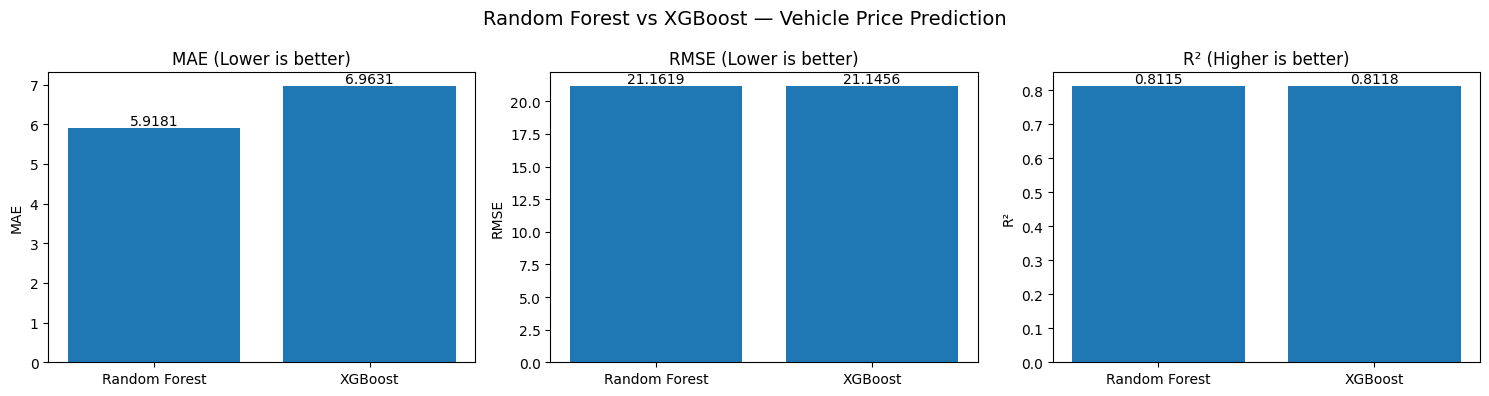

In [22]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("MAE", "Lower is better"),
    ("RMSE", "Lower is better"),
    ("R²", "Higher is better")
]

for ax, (metric, direction) in zip(axes, metrics):
    ax.bar(comparison["Model"], comparison[metric])

    ax.set_title(f"{metric} ({direction})")
    ax.set_ylabel(metric)

    for i, value in enumerate(comparison[metric]):
        ax.text(
            i,
            value,
            f"{value:.4f}",
            ha="center",
            va="bottom"
        )

plt.suptitle(
    "Random Forest vs XGBoost — Vehicle Price Prediction",
    fontsize=14
)
plt.tight_layout()
plt.show()


In [23]:

import pandas as pd
import numpy as np

results = X_test.copy()

results["Actual_Price"] = y_test.values
results["RF_Predicted"] = rf_predictions
results["XGB_Predicted"] = xgb_predictions

results["RF_Error"] = abs(
    results["Actual_Price"] - results["RF_Predicted"]
)

results["XGB_Error"] = abs(
    results["Actual_Price"] - results["XGB_Predicted"]
)

print("10 largest Random Forest prediction errors:")

display(
    results.sort_values(
        "RF_Error", ascending=False
    )[[
        "Brand", "Model", "YOM",
        "Actual_Price", "RF_Predicted",
        "XGB_Predicted", "RF_Error", "XGB_Error"
    ]].head(10).round(2)
)

print("\nError by actual price range:")

results["Price_Range"] = pd.cut(
    results["Actual_Price"],
    bins=[0, 25, 50, 100, 200, np.inf],
    labels=["0-25", "25-50", "50-100", "100-200", "200+"]
)

display(
    results.groupby(
        "Price_Range", observed=True
    ).agg(
        Count=("Actual_Price", "size"),
        RF_MAE=("RF_Error", "mean"),
        XGB_MAE=("XGB_Error", "mean")
    ).round(3)
)


10 largest Random Forest prediction errors:


,Brand,Model,YOM,Actual_Price,RF_Predicted,XGB_Predicted,RF_Error,XGB_Error
8402,TOYOTA,LEXUS 600HL,2011,790.00,64.54,61.290001,725.46,728.71
6622,TESLA,MODEL 3,2024,347.50,65.22,136.630005,282.28,210.87
6623,TESLA,MODEL 3,2024,375.00,177.08,206.750000,197.92,168.25
8255,TOYOTA,CROWN,2015,316.06,204.16,220.000000,111.91,96.07
2943,NISSAN,FB15 SUPER SALOON,2024,43.50,150.45,131.770004,106.95,88.27
131,BMW,530E,2017,364.50,277.74,290.109985,86.76,74.39
106,BMW,320I E90,2006,116.00,30.88,72.269997,85.12,43.73
1730,MERCEDES-BENZ,E200,2016,405.00,330.60,325.820007,74.40,79.18
132,BMW,530I M SPORT,2017,460.00,391.53,365.350006,68.47,94.65
1741,MERCEDES-BENZ,E220 CDI,2017,375.00,308.97,268.730011,66.03,106.27



Error by actual price range:


,Count,RF_MAE,XGB_MAE
Price_Range,,,
0-25,446,3.919,4.828
25-50,609,3.960,4.854
50-100,720,4.805,5.804
100-200,146,12.153,14.679
200+,33,65.790,65.887


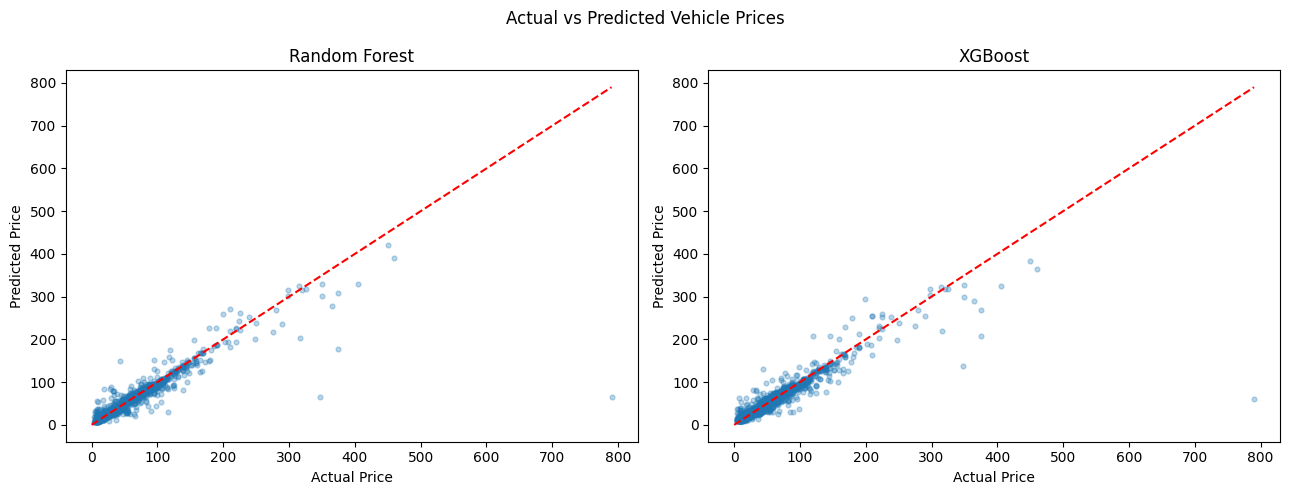

In [24]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Random Forest", rf_predictions),
    ("XGBoost", xgb_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    ax.scatter(
        y_test,
        predictions,
        alpha=0.3,
        s=12
    )

    max_price = max(
        y_test.max(),
        predictions.max()
    )

    ax.plot(
        [0, max_price],
        [0, max_price],
        "--",
        color="red"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Price")
    ax.set_ylabel("Predicted Price")

plt.suptitle("Actual vs Predicted Vehicle Prices")
plt.tight_layout()
plt.show()


In [25]:

# Choose a held-out test record
sample_index = 5

single_vehicle = X_test.iloc[[sample_index]]
actual_price = y_test.iloc[sample_index]

# Predictions from both models
rf_single = rf_model.predict(single_vehicle)[0]
xgb_single = xgb_model.predict(single_vehicle)[0]

print("SINGLE VEHICLE INFERENCE")
print("=" * 45)

print("\nVehicle details:")
display(single_vehicle.T)

print("\nACTUAL VS PREDICTED")
print(f"Actual price:        {actual_price:.2f}")
print(f"Random Forest:       {rf_single:.2f}")
print(f"XGBoost:            {xgb_single:.2f}")

print("\nAbsolute prediction errors:")
print(f"Random Forest: {abs(actual_price-rf_single):.2f}")
print(f"XGBoost:      {abs(actual_price-xgb_single):.2f}")


SINGLE VEHICLE INFERENCE

Vehicle details:


,4913
Brand,SUZUKI
Model,CELERIO ZXI
YOM,2014
Engine (cc),1000.0
Gear,Manual
Fuel Type,Petrol
Millage(KM),121000.0
Town,Weligama
Leasing,No Leasing
Condition,USED



ACTUAL VS PREDICTED
Actual price:        44.50
Random Forest:       34.01
XGBoost:            30.50

Absolute prediction errors:
Random Forest: 10.49
XGBoost:      14.00


In [26]:

import joblib
from pathlib import Path

model_dir = Path("/content/vehicle_models")
model_dir.mkdir(exist_ok=True)

rf_path = model_dir / "random_forest_pipeline.pkl"
xgb_path = model_dir / "xgboost_pipeline.pkl"

joblib.dump(rf_model, rf_path)
joblib.dump(xgb_model, xgb_path)

print("Saved models:")
print(rf_path)
print(xgb_path)

print("\nFile sizes:")
for path in [rf_path, xgb_path]:
    print(path.name, round(path.stat().st_size / 1024**2, 2), "MB")


Saved models:
/content/vehicle_models/random_forest_pipeline.pkl
/content/vehicle_models/xgboost_pipeline.pkl

File sizes:
random_forest_pipeline.pkl 22.53 MB
xgboost_pipeline.pkl 0.66 MB


In [27]:

loaded_rf = joblib.load(rf_path)
loaded_xgb = joblib.load(xgb_path)

loaded_rf_prediction = loaded_rf.predict(single_vehicle)[0]
loaded_xgb_prediction = loaded_xgb.predict(single_vehicle)[0]

assert np.isclose(loaded_rf_prediction, rf_single)
assert np.isclose(loaded_xgb_prediction, xgb_single)

print("Model export and reload verification PASSED.")
print("Random Forest:", round(loaded_rf_prediction, 2))
print("XGBoost:", round(loaded_xgb_prediction, 2))


Model export and reload verification PASSED.
Random Forest: 34.01
XGBoost: 30.5


In [28]:

from pathlib import Path

app_code = r'''
import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

st.set_page_config(
    page_title="Sri Lanka Vehicle Price Predictor",
    page_icon="🚗",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent

@st.cache_resource
def load_models():
    rf = joblib.load(BASE_DIR / "models" / "random_forest_pipeline.pkl")
    xgb = joblib.load(BASE_DIR / "models" / "xgboost_pipeline.pkl")
    return rf, xgb

rf_model, xgb_model = load_models()

st.title("🚗 Sri Lankan Used Vehicle Price Predictor")
st.write(
    "Compare Random Forest and XGBoost predictions "
    "using Sri Lankan used vehicle listing data."
)

st.info(
    "This is an educational ML demonstration. "
    "Predictions estimate advertised listing prices, "
    "not verified market values. "
    "Price units require confirmation from the dataset source."
)

st.subheader("Enter Vehicle Details")

col1, col2, col3 = st.columns(3)

with col1:
    brand = st.text_input("Brand", value="SUZUKI")
    model = st.text_input("Model", value="CELERIO ZXI")
    yom = st.number_input(
        "Year of Manufacture",
        min_value=1950,
        max_value=2026,
        value=2014
    )
    engine = st.number_input(
        "Engine Capacity (cc)",
        min_value=0,
        value=1000
    )
    mileage = st.number_input(
        "Mileage (KM)",
        min_value=0,
        value=121000
    )

with col2:
    gear = st.selectbox(
        "Transmission",
        ["Automatic", "Manual"],
        index=1
    )
    fuel = st.selectbox(
        "Fuel Type",
        ["Petrol", "Hybrid", "Diesel", "Electric"]
    )
    town = st.text_input("Town", value="Weligama")
    leasing = st.selectbox(
        "Leasing",
        ["No Leasing", "Ongoing Lease"]
    )
    condition = st.selectbox(
        "Condition",
        ["USED", "NEW"]
    )

with col3:
    ac = st.selectbox(
        "Air Conditioning",
        ["Available", "Not_Available"]
    )
    steering = st.selectbox(
        "Power Steering",
        ["Available", "Not_Available"]
    )
    mirror = st.selectbox(
        "Power Mirror",
        ["Available", "Not_Available"]
    )
    window = st.selectbox(
        "Power Window",
        ["Available", "Not_Available"]
    )

vehicle = pd.DataFrame([{
    "Brand": brand.strip().upper(),
    "Model": model.strip().upper(),
    "YOM": yom,
    "Engine (cc)": engine,
    "Gear": gear,
    "Fuel Type": fuel,
    "Millage(KM)": mileage,
    "Town": town.strip(),
    "Leasing": leasing,
    "Condition": condition,
    "AIR CONDITION": ac,
    "POWER STEERING": steering,
    "POWER MIRROR": mirror,
    "POWER WINDOW": window
}])

st.divider()

if st.button("Predict Vehicle Price", type="primary"):
    rf_price = rf_model.predict(vehicle)[0]
    xgb_price = xgb_model.predict(vehicle)[0]

    st.subheader("Prediction Results")

    left, right = st.columns(2)

    with left:
        st.metric(
            "Random Forest Prediction",
            f"{rf_price:,.2f}"
        )
        st.caption("Initial test MAE: 5.9181")

    with right:
        st.metric(
            "XGBoost Prediction",
            f"{xgb_price:,.2f}"
        )
        st.caption("Initial test MAE: 6.9631")

    st.caption(
        "Prices are in original dataset units. "
        "These predictions are estimates and may "
        "be unreliable for rare or premium vehicles."
    )

    st.subheader("Input Vehicle")
    st.dataframe(vehicle, use_container_width=True)
'''

project_dir = Path("/content/vehicle_price_project")
models_dir = project_dir / "models"

models_dir.mkdir(parents=True, exist_ok=True)

(project_dir / "app.py").write_text(
    app_code,
    encoding="utf-8"
)

print("Created:", project_dir / "app.py")


Created: /content/vehicle_price_project/app.py


In [29]:

import shutil

shutil.copy2(
    rf_path,
    models_dir / "random_forest_pipeline.pkl"
)

shutil.copy2(
    xgb_path,
    models_dir / "xgboost_pipeline.pkl"
)

print("Project files:")

for file in project_dir.rglob("*"):
    if file.is_file():
        print(
            file.relative_to(project_dir),
            round(file.stat().st_size / 1024**2, 2),
            "MB"
        )


Project files:
requirements.txt 0.0 MB
app.py 0.0 MB
README.md 0.0 MB
models/random_forest_pipeline.pkl 22.53 MB
models/xgboost_pipeline.pkl 0.66 MB


In [30]:

import importlib.metadata as metadata

packages = [
    "streamlit",
    "pandas",
    "numpy",
    "scikit-learn",
    "xgboost",
    "joblib"
]

requirements = []

for package in packages:
    try:
        version = metadata.version(package)
        requirements.append(f"{package}=={version}")
    except metadata.PackageNotFoundError:
        requirements.append(package)

(project_dir / "requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

readme = """# Sri Lankan Used Vehicle Price Prediction

MSc Applied Machine Learning - Class Activity

## Objective
Compare Random Forest and XGBoost regression models
using a Sri Lankan used vehicle listing dataset.

## Dataset
Source:
https://www.kaggle.com/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset

The dataset contains 9,788 original records.
After removing 18 exact duplicate rows, 9,770 records remain.

## Model Evaluation

| Metric | Random Forest | XGBoost |
|---|---:|---:|
| MAE | 5.9181 | 6.9631 |
| RMSE | 21.1619 | 21.1456 |
| R2 | 0.8115 | 0.8118 |

These are initial test results without additional
hyperparameter optimization.

## Run Application

Install dependencies:

pip install -r requirements.txt

Start the application:

streamlit run app.py

## Limitations

- Prices represent advertised listing values.
- Original price units still require confirmation.
- Mileage values are all multiples of 11,000 km.
- Both models struggle with rare premium vehicles.
- The dataset covers December 2024 to February 2025.
- This is an educational demonstration.
"""

(project_dir / "README.md").write_text(
    readme,
    encoding="utf-8"
)

print("requirements.txt and README.md created.")


requirements.txt and README.md created.


In [31]:

import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "/content/vehicle_price_project",
    "zip",
    root_dir="/content",
    base_dir="vehicle_price_project"
)

print("Archive created:", archive_path)

files.download(archive_path)


Archive created: /content/vehicle_price_project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:

%pip -q install streamlit


In [33]:

import subprocess
import time

streamlit_process = subprocess.Popen(
    [
        "streamlit",
        "run",
        str(project_dir / "app.py"),
        "--server.port=8501",
        "--server.headless=true"
    ],
    stdout=open("/content/streamlit.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process ID:", streamlit_process.pid)
print("Running:", streamlit_process.poll() is None)


Streamlit process ID: 7690
Running: True


In [34]:

from google.colab import output

output.serve_kernel_port_as_window(8501)


Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [35]:

expected_mileage = (2025 - df_clean["YOM"]) * 11000

matches = np.isclose(
    df_clean["Millage(KM)"],
    expected_mileage
)

print("Matching records:", matches.sum())
print("Total records:", len(matches))
print("Match percentage:", round(matches.mean() * 100, 2))

display(
    df_clean.loc[
        ~matches,
        ["Brand", "Model", "YOM", "Millage(KM)"]
    ].head(10)
)


Matching records: 9770
Total records: 9770
Match percentage: 100.0


,Brand,Model,YOM,Millage(KM)


In [36]:

from sklearn.model_selection import train_test_split

# Remove redundant mileage and previously excluded fields
X = df_clean.drop(columns=[
    "Price",
    "Date",
    "Millage(KM)"
])

y = df_clean["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Rebuild feature lists
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

assert "Millage(KM)" not in X_train.columns


Training records: 7816
Testing records: 1954
Numeric features: ['YOM', 'Engine (cc)']
Categorical features: ['Brand', 'Model', 'Gear', 'Fuel Type', 'Town', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']


In [37]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.base import clone

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"),
     numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ]), categorical_features)
])

rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", RandomForestRegressor(
        n_estimators=150,
        max_depth=18,
        min_samples_split=4,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

print("New pipelines created without mileage.")


New pipelines created without mileage.


In [38]:

import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

for name, model in [
    ("Random Forest", rf_model),
    ("XGBoost", xgb_model)
]:
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, predictions
        )),
        "R2": r2_score(y_test, predictions),
        "Training Time (s)": elapsed
    })

comparison_updated = pd.DataFrame(results)

print("UPDATED MODEL COMPARISON — WITHOUT MILEAGE")
display(comparison_updated.round(4))

print("\nBest model by MAE:")
print(
    comparison_updated.loc[
        comparison_updated["MAE"].idxmin(), "Model"
    ]
)


UPDATED MODEL COMPARISON — WITHOUT MILEAGE


,Model,MAE,RMSE,R2,Training Time (s)
0,Random Forest,5.8880,21.1365,0.8119,27.0736
1,XGBoost,6.9775,21.3378,0.8083,1.4263



Best model by MAE:
Random Forest


In [39]:

import joblib
from pathlib import Path

models_dir = Path("/content/vehicle_price_project/models")
models_dir.mkdir(parents=True, exist_ok=True)

rf_path = models_dir / "random_forest_pipeline.pkl"
xgb_path = models_dir / "xgboost_pipeline.pkl"

joblib.dump(rf_model, rf_path)
joblib.dump(xgb_model, xgb_path)

print("Updated models saved successfully!")
print("Random Forest:", rf_path)
print("XGBoost:", xgb_path)


Updated models saved successfully!
Random Forest: /content/vehicle_price_project/models/random_forest_pipeline.pkl
XGBoost: /content/vehicle_price_project/models/xgboost_pipeline.pkl


In [40]:

# Select a held-out test record
single_vehicle = X_test.iloc[[5]]

# Load saved models
loaded_rf = joblib.load(rf_path)
loaded_xgb = joblib.load(xgb_path)

# Predict
rf_prediction = loaded_rf.predict(single_vehicle)[0]
xgb_prediction = loaded_xgb.predict(single_vehicle)[0]

print("VEHICLE DETAILS")
display(single_vehicle.T)

print("\nACTUAL PRICE:", round(y_test.iloc[5], 2))
print("RF PREDICTION:", round(rf_prediction, 2))
print("XGB PREDICTION:", round(xgb_prediction, 2))

assert "Millage(KM)" not in single_vehicle.columns
assert np.isclose(rf_prediction, rf_model.predict(single_vehicle)[0])
assert np.isclose(xgb_prediction, xgb_model.predict(single_vehicle)[0])

print("\nUpdated model verification PASSED!")


VEHICLE DETAILS


,4913
Brand,SUZUKI
Model,CELERIO ZXI
YOM,2014
Engine (cc),1000.0
Gear,Manual
Fuel Type,Petrol
Town,Weligama
Leasing,No Leasing
Condition,USED
AIR CONDITION,Available



ACTUAL PRICE: 44.5
RF PREDICTION: 33.86
XGB PREDICTION: 30.03

Updated model verification PASSED!


In [41]:

from pathlib import Path

app_path = Path("/content/vehicle_price_project/app.py")
app_code = app_path.read_text(encoding="utf-8")

# Remove the mileage input widget
old_mileage_widget = '''    mileage = st.number_input(
        "Mileage (KM)",
        min_value=0,
        value=121000
    )
'''

assert old_mileage_widget in app_code, (
    "Mileage widget not found. Check app.py before editing."
)

app_code = app_code.replace(old_mileage_widget, "")

# Remove mileage from prediction input
old_mileage_feature = '    "Millage(KM)": mileage,\n'

assert old_mileage_feature in app_code, (
    "Mileage feature not found in prediction dictionary."
)

app_code = app_code.replace(old_mileage_feature, "")

# Update model evaluation values
app_code = app_code.replace(
    "Initial test MAE: 5.9181",
    "Updated test MAE: 5.8880"
)

app_code = app_code.replace(
    "Initial test MAE: 6.9631",
    "Updated test MAE: 6.9775"
)

app_path.write_text(app_code, encoding="utf-8")

print("Dashboard updated successfully.")
print("Mileage input removed.")
print("Model evaluation metrics updated.")


Dashboard updated successfully.
Mileage input removed.
Model evaluation metrics updated.


In [42]:

readme_path = Path("/content/vehicle_price_project/README.md")
readme = readme_path.read_text(encoding="utf-8")

readme = readme.replace("5.9181", "5.8880")
readme = readme.replace("21.1619", "21.1365")
readme = readme.replace("0.8115", "0.8119")

readme = readme.replace("6.9631", "6.9775")
readme = readme.replace("21.1456", "21.3378")
readme = readme.replace("0.8118", "0.8083")

readme = readme.replace(
    "- Mileage values are all multiples of 11,000 km.",
    "- Mileage was found to be exactly determined by "
    "manufacturing year: (2025 - YOM) * 11000. "
    "It was removed from the training features."
)

readme_path.write_text(readme, encoding="utf-8")

print("README updated successfully.")


README updated successfully.


In [43]:

import ast
import joblib

app_code = app_path.read_text(encoding="utf-8")

# Validate Python syntax
ast.parse(app_code)

# Confirm outdated mileage input was removed
assert '"Millage(KM)": mileage' not in app_code
assert 'mileage = st.number_input' not in app_code

# Confirm metrics
assert "5.8880" in app_code
assert "6.9775" in app_code

# Confirm model feature compatibility
test_vehicle = X_test.iloc[[5]]

rf_loaded = joblib.load(
    "/content/vehicle_price_project/models/random_forest_pipeline.pkl"
)

xgb_loaded = joblib.load(
    "/content/vehicle_price_project/models/xgboost_pipeline.pkl"
)

rf_value = rf_loaded.predict(test_vehicle)[0]
xgb_value = xgb_loaded.predict(test_vehicle)[0]

print("Application syntax: PASSED")
print("Mileage removal: PASSED")
print("Model loading: PASSED")
print("RF prediction:", round(rf_value, 2))
print("XGBoost prediction:", round(xgb_value, 2))


Application syntax: PASSED
Mileage removal: PASSED
Model loading: PASSED
RF prediction: 33.86
XGBoost prediction: 30.03


In [44]:

import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "/content/vehicle_price_project_updated",
    "zip",
    root_dir="/content",
    base_dir="vehicle_price_project"
)

print("Updated ZIP:", archive_path)

files.download(archive_path)


Updated ZIP: /content/vehicle_price_project_updated.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>